# TP5
## A) Description et visualisation des données

1) On veut d'abord créer notre fonction analyse(X,Y) qui nous fait un résumé un jeu de données :

In [178]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as ADL
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans as KM
from sklearn.metrics import silhouette_score

iris = load_iris()
X = iris.data
y = iris.target
df = pd.DataFrame(data = iris.data, columns= iris.feature_names)
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


2) On veut aussi qu'elle nous fasse une ACP et une ADL

In [179]:
def analyse(X,y):
    noms = [f"Col_{i+1}" for i in range(X.shape[1])]

    df = pd.DataFrame(data = X, columns= noms)
    print(df.describe())

    pca = PCA(n_components=2)
    ACPX = pca.fit_transform(X)
    df_ACPX = pd.DataFrame(data = ACPX, columns=['Composante 1','Composante 2'])
    df_ACPX['cible'] = y

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
    df_ACPX['Composante 1'], 
    df_ACPX['Composante 2'], 
    c=df_ACPX['cible'])
    plt.legend(*scatter.legend_elements(), title="Classes")
    plt.title('Visualisation de l_ACP')
    plt.xlabel('AXE ACP 1')
    plt.ylabel('AXE ACP 2')
    plt.show()

    adl = ADL(n_components=2)
    ADLX = adl.fit_transform(X,y)
    df_ADLX = pd.DataFrame(data=ADLX, columns=['Axe ADL 1', 'Axe ADL 2'])
    df_ADLX['cible'] = y

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        df_ADLX['Axe ADL 1'], 
        df_ADLX['Axe ADL 2'], 
        c=df_ADLX['cible'])

    plt.legend(*scatter.legend_elements(), title="Classes")
    plt.title("Visualisation de l_ADL")
    plt.xlabel("AXE ADL 1")
    plt.ylabel("AXE ADL 2")
    plt.show()





            Col_1       Col_2       Col_3       Col_4
count  150.000000  150.000000  150.000000  150.000000
mean     5.843333    3.057333    3.758000    1.199333
std      0.828066    0.435866    1.765298    0.762238
min      4.300000    2.000000    1.000000    0.100000
25%      5.100000    2.800000    1.600000    0.300000
50%      5.800000    3.000000    4.350000    1.300000
75%      6.400000    3.300000    5.100000    1.800000
max      7.900000    4.400000    6.900000    2.500000


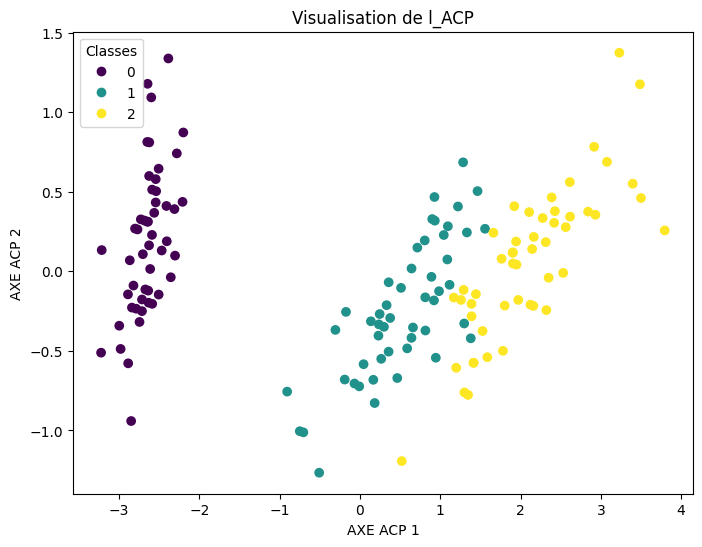

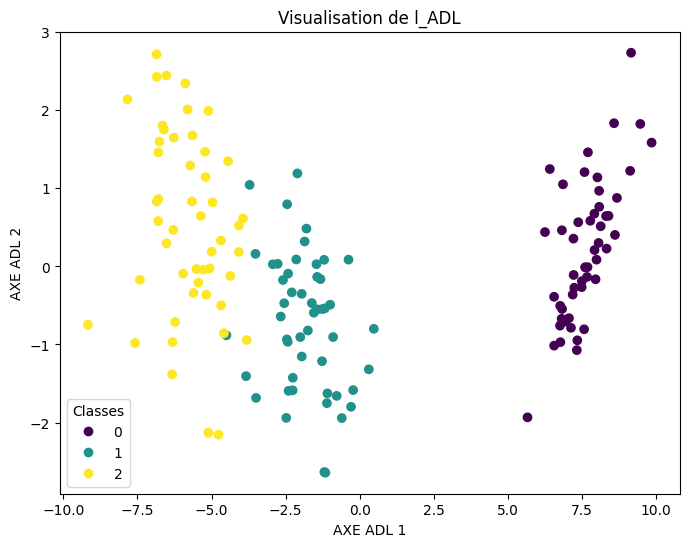

In [180]:
analyse(X,y)

## Explication des principes de l'ACP et de l'ADL :

### ACP :

On cherche le meilleur espace de représentation sur lequel projeté nos données tout en cherchant à maximiser la variance entre les données pour conserver une bonne visualisation.

### ADL :

On cherche l'espace de représentation qui permet de conserver au mieux les clusters, de maximiser la variance entre les clusters et minimise la variance au sein d'un même groupe.

## B) K-means

1) On écrit la fonction qui le numéro de cluster de chaque données.

In [181]:
def K_means(X,k):
    v = X.shape[1]
    c =[]
    for i in range(k):
        c.append(np.random.randn(v))
    c = np.array(c)
    d = np.linalg.norm(X[:, np.newaxis] - c, axis=2)
    g = np.argmin(d, axis=1)
    while True:
        d = np.linalg.norm(X[:, np.newaxis] - c, axis=2)
        g_new = np.argmin(d, axis=1)

        if np.array_equal(g_new, g):
            break
        g = g_new

        c1 = []
        for i in range(k):
            points_groupe = X[g == i]
            if len(points_groupe) > 0:
                c1.append(points_groupe.mean(axis=0))
            else:
                c1.append(X[np.random.randint(len(X))])
        c = np.array(c1)

    return g

In [182]:
K_means(X,10)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

On compare avec lla fonction kmeans de sklearn :

In [183]:
K = KM(10,init='random',n_init=1)
K2 = K.fit_predict(X,10)
print(K2)

[9 0 0 0 9 9 0 9 0 0 9 0 0 0 9 9 9 9 9 9 9 9 0 9 0 0 9 9 9 0 0 9 9 9 0 0 9
 9 0 9 9 0 0 9 9 0 9 0 9 0 5 5 5 2 5 2 5 2 5 2 2 2 2 5 2 5 2 2 5 2 7 2 7 5
 5 5 5 4 5 2 2 2 2 7 2 5 5 5 2 2 2 5 2 2 2 2 2 5 2 2 3 7 8 4 3 6 2 1 4 8 4
 4 4 7 7 3 4 6 6 7 8 7 6 7 3 1 7 7 4 1 1 6 4 7 7 1 3 4 7 4 3 4 7 8 3 4 7 4
 3 7]


3) On veut stabiliser nos résultats et sélectionner automatiquement le nombre de groupe.

In [184]:
meilleur_score = -1
meilleur_k = None
meilleure_solution = None

for k in range(2, 11):
    for _ in range(10):
        labels_potentiels = K_means(X, k)
        if len(np.unique(labels_potentiels)) < 2:
            continue
        score = silhouette_score(X, labels_potentiels)
        if score > meilleur_score:
            meilleur_score = score
            meilleur_k = k
            meilleure_solution = labels_potentiels

print(meilleur_k)

4


Mes clusters varies entre 2 et 5 c'est déjà plus probant que à la question 1)

4) On affiche nos clusters obtenus sur l'acp à la partie A a coté de la figure colorés par les labels Y :

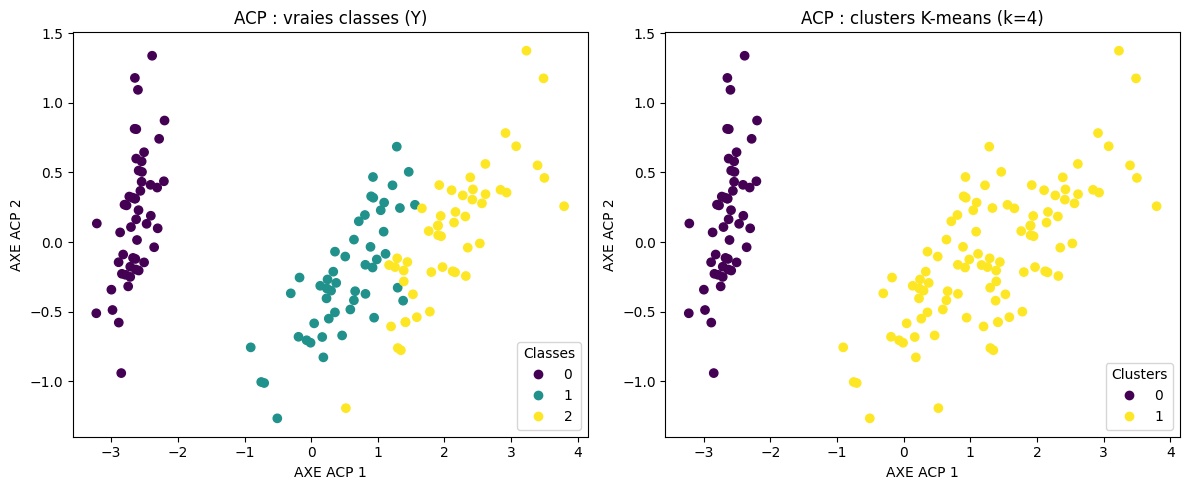

In [185]:
pca = PCA(n_components=2)
ACPX = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sc0 = axes[0].scatter(ACPX[:, 0], ACPX[:, 1], c=y)
axes[0].set_title("ACP : vraies classes (Y)")
axes[0].legend(*sc0.legend_elements(), title="Classes")

sc1 = axes[1].scatter(ACPX[:, 0], ACPX[:, 1], c=meilleure_solution)
axes[1].set_title(f"ACP : clusters K-means (k={meilleur_k})")
axes[1].legend(*sc1.legend_elements(), title="Clusters")

for ax in axes:
    ax.set_xlabel("AXE ACP 1")
    ax.set_ylabel("AXE ACP 2")

plt.tight_layout()
plt.show()

Les groupes sont assez cohérents avec les classes vu que deux groupes se chevauchent légèrement.

## C) Test de différents algorithmes de clustering

1) on modifie notre fonction pour qu'elle suggère les clusteerring

In [186]:
from sklearn.metrics import silhouette_score

def analyse(X,y):
    noms = [f"Col_{i+1}" for i in range(X.shape[1])]

    df = pd.DataFrame(data = X, columns= noms)
    print(df.describe())

    pca = PCA(n_components=2)
    ACPX = pca.fit_transform(X)
    df_ACPX = pd.DataFrame(data = ACPX, columns=['Composante 1','Composante 2'])
    df_ACPX['cible'] = y

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
    df_ACPX['Composante 1'], 
    df_ACPX['Composante 2'], 
    c=df_ACPX['cible'])
    plt.legend(*scatter.legend_elements(), title="Classes")
    plt.title('Visualisation de l_ACP')
    plt.xlabel('AXE ACP 1')
    plt.ylabel('AXE ACP 2')
    plt.show()

    adl = ADL(n_components=2)
    ADLX = adl.fit_transform(X,y)
    df_ADLX = pd.DataFrame(data=ADLX, columns=['Axe ADL 1', 'Axe ADL 2'])
    df_ADLX['cible'] = y

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        df_ADLX['Axe ADL 1'], 
        df_ADLX['Axe ADL 2'], 
        c=df_ADLX['cible'])

    plt.legend(*scatter.legend_elements(), title="Classes")
    plt.title("Visualisation de l_ADL")
    plt.xlabel("AXE ADL 1")
    plt.ylabel("AXE ADL 2")
    plt.show()

    meilleur_score = -1
    meilleur_k = None
    meilleure_solution = None

    for k in range(2, 11):
        for _ in range(10):
            labels = K_means(X, k)
            if len(np.unique(labels)) < 2:
                continue
            score = silhouette_score(X, labels)
            if score > meilleur_score:
                meilleur_score = score
                meilleur_k = k
                meilleure_solution = labels

    print(f"Clustering suggéré : k = {meilleur_k} (silhouette = {meilleur_score:.2f})")

    return meilleur_k, meilleure_solution

            Col_1       Col_2       Col_3       Col_4
count  150.000000  150.000000  150.000000  150.000000
mean     5.843333    3.057333    3.758000    1.199333
std      0.828066    0.435866    1.765298    0.762238
min      4.300000    2.000000    1.000000    0.100000
25%      5.100000    2.800000    1.600000    0.300000
50%      5.800000    3.000000    4.350000    1.300000
75%      6.400000    3.300000    5.100000    1.800000
max      7.900000    4.400000    6.900000    2.500000


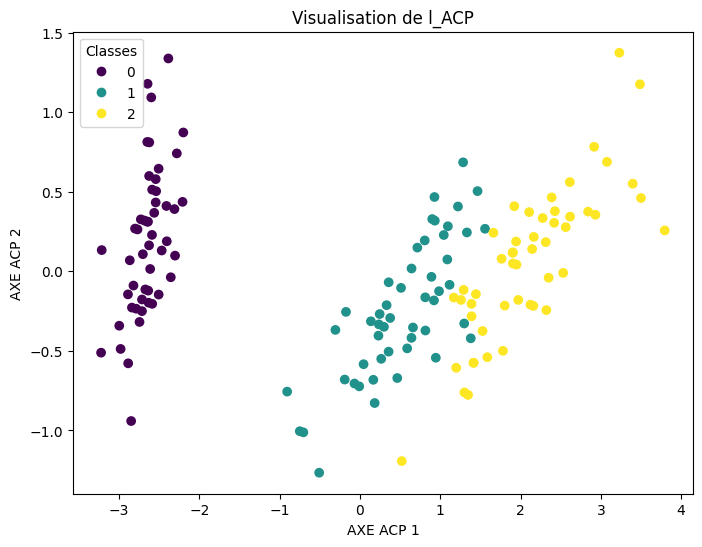

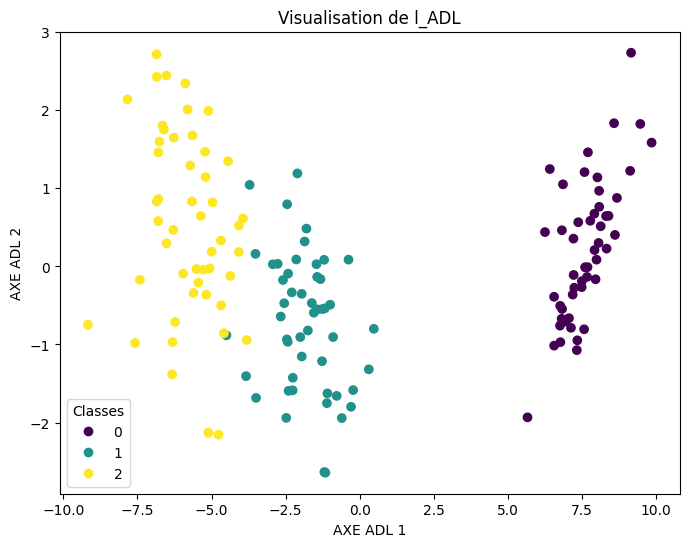

Clustering suggéré : k = 4 (silhouette = 0.69)
4
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3]


In [187]:
meilleur_k, meilleure_solution = analyse(X, y)
print(meilleur_k)
print(meilleure_solution)

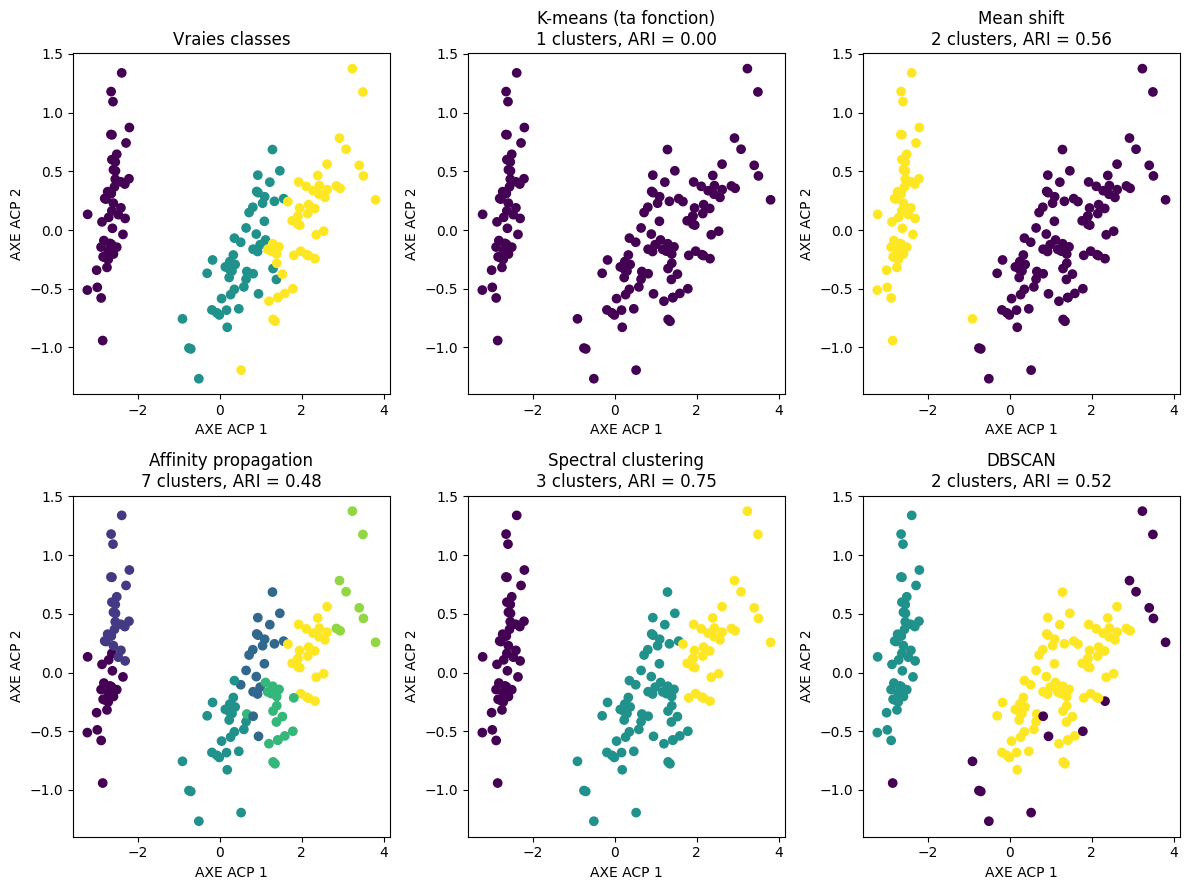

In [188]:
from sklearn.cluster import MeanShift, AffinityPropagation, SpectralClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score

k = len(np.unique(y))

resultats = {
    "K-means (ta fonction)": K_means(X, k),
    "Mean shift": MeanShift().fit_predict(X),
    "Affinity propagation": AffinityPropagation(random_state=0).fit_predict(X),
    "Spectral clustering": SpectralClustering(n_clusters=k, random_state=0).fit_predict(X),
    "DBSCAN": DBSCAN().fit_predict(X),
}

pca = PCA(n_components=2)
ACPX = pca.fit_transform(X)

fig, axes = plt.subplots(2, 3, figsize=(12, 9))
axes = axes.ravel()

axes[0].scatter(ACPX[:, 0], ACPX[:, 1], c=y)
axes[0].set_title("Vraies classes")

for ax, (nom, labels) in zip(axes[1:], resultats.items()):
    ax.scatter(ACPX[:, 0], ACPX[:, 1], c=labels)
    nb = len(set(labels)) - (1 if -1 in labels else 0)
    ari = adjusted_rand_score(y, labels)
    ax.set_title(f"{nom}\n{nb} clusters, ARI = {ari:.2f}")

for ax in axes:
    ax.set_xlabel("AXE ACP 1")
    ax.set_ylabel("AXE ACP 2")

plt.tight_layout()
plt.show()

2) On calcul les scores internes et externes :

In [189]:
from sklearn.metrics import (davies_bouldin_score, silhouette_score,
                             adjusted_mutual_info_score, adjusted_rand_score)

def evaluer(X, y, resultats):
    lignes = []
    for nom, labels in resultats.items():
        if len(np.unique(labels)) >= 2:
            db = davies_bouldin_score(X, labels)
            sil = silhouette_score(X, labels)
        else:
            db, sil = np.nan, np.nan
        ami = adjusted_mutual_info_score(y, labels)
        ari = adjusted_rand_score(y, labels)

        lignes.append({"Méthode": nom,
                       "Davies-Bouldin": db,
                       "Silhouette": sil,
                       "AMI": ami,
                       "ARI": ari})

    tableau = pd.DataFrame(lignes).set_index("Méthode")
    print(tableau.round(3))
    return tableau

tableau = evaluer(X, y, resultats)

                       Davies-Bouldin  Silhouette    AMI    ARI
Méthode                                                        
K-means (ta fonction)             NaN         NaN  0.000  0.000
Mean shift                      0.389       0.686  0.697  0.558
Affinity propagation            0.985       0.347  0.660  0.481
Spectral clustering             0.654       0.555  0.795  0.746
DBSCAN                          7.222       0.486  0.599  0.521


Un score interne on évalue sans vérification, sans étiquette en regardant comment les données sont organisés alors qu'en score externe on peut vérifier exactement ce qui a déjà été labellisé.

3) La meilleure méthode de clustering semble être le spectral clusturing qui obtient les scores externe AMI et ARI les plus proche de 1. On pourrait aussi considéré le mean shift qui a de pas trop mauvais scores en scores externes et de bons scores internes.

# D) Test de différents algorithmes de classification :

1) On va redéfinir notre fonction analyse pour qu'elle utilise la méthode du leave one out pour prédire le label de chaque observation.